In [17]:
import numpy as np
from matplotlib import pyplot as plt
import torch
import torch.nn as nn

### TASK 2

##### task 2.1

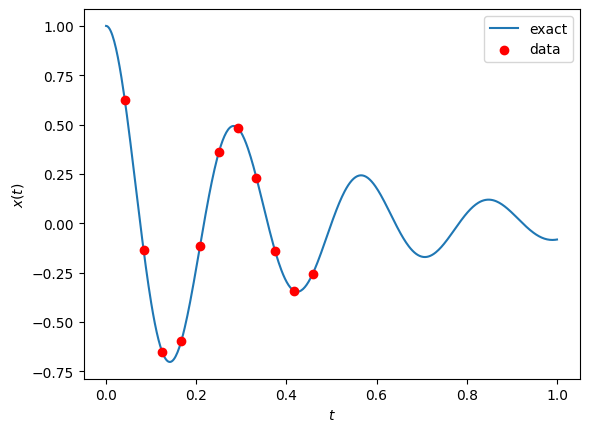

1.0


In [14]:
import numpy as np
import matplotlib.pyplot as plt

# parameters
m, mu, k = 1, 5, 500
delta = mu / (2*m)
w0 = np.sqrt(k)
w = np.sqrt(w0**2 - delta**2)
phi = np.arctan(-delta / w)
A = 1 / (2*np.cos(phi))

def x(t):
    return np.exp(-delta*t) * 2*A * np.cos(phi + w*t)

# task 2.1: 10 data points in the open interval (0, 0.5)
t_data = np.linspace(0, 0.5, 13)[1:-1]
x_data = x(t_data)

# check
t_dense = np.linspace(0, 1, 500)
plt.plot(t_dense, x(t_dense), label="exact")
plt.scatter(t_data, x_data, color="red", zorder=3, label="data")
plt.xlabel("$t$"); plt.ylabel("$x(t)$"); plt.legend()
plt.show()

print(x(0.0))   # should be 1.0

##### Task 2.2

In [23]:
t_train = torch.tensor(t_data, dtype=torch.float32).view(-1, 1)
x_train = torch.tensor(x_data, dtype=torch.float32).view(-1, 1)
t_train, x_train

(tensor([[0.0417],
         [0.0833],
         [0.1250],
         [0.1667],
         [0.2083],
         [0.2500],
         [0.2917],
         [0.3333],
         [0.3750],
         [0.4167],
         [0.4583]]),
 tensor([[ 0.6227],
         [-0.1373],
         [-0.6544],
         [-0.5974],
         [-0.1159],
         [ 0.3595],
         [ 0.4836],
         [ 0.2320],
         [-0.1413],
         [-0.3414],
         [-0.2552]]))

epoch     0 | loss 1.62e-01
epoch  2000 | loss 7.16e-02
epoch  4000 | loss 1.62e-02
epoch  6000 | loss 2.13e-03
epoch  8000 | loss 1.47e-04


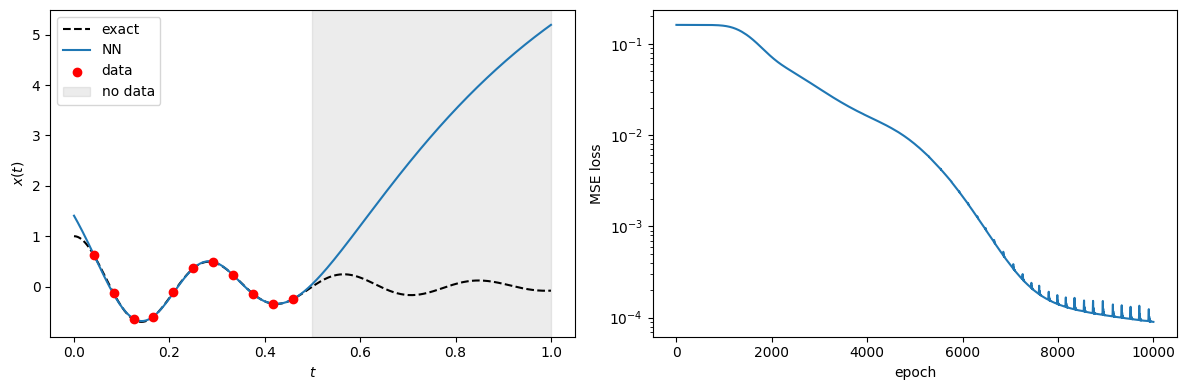

In [53]:


torch.manual_seed(0)

#tensors of shape (N, 1)
t_train = torch.tensor(t_data, dtype=torch.float32).view(-1, 1)
x_train = torch.tensor(x_data, dtype=torch.float32).view(-1, 1)

# shallow network: 1 hidden layer, tanh, linear output
class ShallowNet(nn.Module):
    def __init__(self, n_hidden=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, n_hidden),
            nn.Tanh(),
            nn.Linear(n_hidden, 1),
        )
    def forward(self, t):
        return self.net(t)

model = ShallowNet(n_hidden=32)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

# training
n_epochs = 10000
losses = []
for epoch in range(n_epochs):
    optimizer.zero_grad()
    loss = loss_fn(model(t_train), x_train)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 2000 == 0:
        print(f"epoch {epoch:5d} | loss {loss.item():.2e}")

# inference on (0, 1)
t_test = torch.linspace(0, 1, 500).view(-1, 1)
with torch.no_grad():
    x_pred = model(t_test).numpy().ravel()

# plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(t_dense, x(t_dense), "k--", label="exact")
ax[0].plot(t_test.numpy().ravel(), x_pred, label="NN")
ax[0].scatter(t_data, x_data, color="red", zorder=3, label="data")
ax[0].axvspan(0.5, 1.0, color="gray", alpha=0.15, label="no data")
ax[0].set_xlabel("$t$"); ax[0].set_ylabel("$x(t)$"); ax[0].legend()

ax[1].semilogy(losses)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("MSE loss")

plt.tight_layout()
plt.show()